In [1]:
from google.colab import files

uploaded = files.upload()

Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
filename = "UNSW_NB15_training-set.csv"
df = pd.read_csv(filename)
df.columns = df.columns.str.strip()
print("Размер таблицы:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())
display(df.head())

Размер таблицы: (175341, 45)

Названия столбцов:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


# Анализ сетевого трафика для обнаружения потенциальных атак
## 1. Постановка задачи
### Бизнес-постановка
В корпоративных сетях ежедневно происходит большое количество сетевых соединений. Некоторые из них могут быть связаны с попытками атак на информационную инфраструктуру. Ручная проверка всех соединений требует времени специалистов по информационной безопасности.
Цель проекта - исследовать характеристики сетевого трафика и подготовить основу для разработки инструмента, который будет отличать обычные соединения от соединений, помеченных как подозрительные. Такой инструмент может использоваться для предварительного отбора событий, требующих дополнительной проверки специалистом.
### Постановка ML-задачи
Задача машинного обучения заключается в бинарной классификации сетевых соединений.
- `0` - обычное сетевое соединение;
- `1` - подозрительное сетевое соединение.
В качестве входных признаков рассматриваются длительность соединения, количество переданных байтов и пакетов, протокол и другие характеристики трафика. Целевая переменная - `label`.
### Описание данных
Для исследования используется открытый набор данных UNSW-NB15, содержащий размеченные записи обычного и атакующего сетевого трафика. В работе используется тренировочный CSV-файл. На данном этапе выполняется разведочный анализ данных, который поможет оценить их качество, распределения признаков и возможные закономерности.
Источник: https://research.unsw.edu.au/projects/unsw-nb15-dataset

## 2. Выбор метрик качества
Для будущей модели выбраны Recall, Precision и F1-score. Основной метрикой будет Recall для класса подозрительных соединений, поскольку пропуск потенциально опасного соединения может привести к тому, что атака останется незамеченной. Precision позволит оценить долю действительно подозрительных соединений среди отмеченных моделью как атаки, а F1-score поможет оценить баланс между Precision и Recall.
Accuracy не используется как единственная метрика, поскольку при дисбалансе классов она может быть высокой даже у модели, которая пропускает значительную часть атак

In [3]:
#3.Первичный анализ данных

print("Размер набора данных:", df.shape)
print("\nТипы данных:")
print(df.dtypes.value_counts())
print("\nИнформация о столбцах:")
df.info()
print("\nКоличество пропусков:")
print(df.isnull().sum().sort_values(ascending=False).head(15))
print("\nКоличество полных дубликатов:", df.duplicated().sum())
print("\nОсновные статистики числовых признаков:")
display(df.describe().T)


Размер набора данных: (175341, 45)

Типы данных:
int64      30
float64    11
object      4
Name: count, dtype: int64

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload   

,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


# 3. EDA

Количество соединений по классам:
label
0     56000
1    119341
Name: count, dtype: int64

Доли классов, %:
label
1    68.06
0    31.94
Name: proportion, dtype: float64


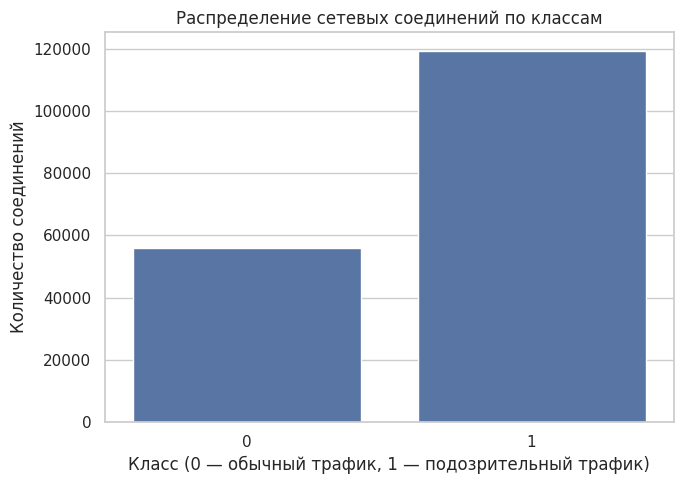

In [6]:
#3.1.Распределение классов

class_counts = df["label"].value_counts().sort_index()
print("Количество соединений по классам:")
print(class_counts)
print("\nДоли классов, %:")
print((df["label"].value_counts(normalize=True) * 100).round(2))
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")
plt.title("Распределение сетевых соединений по классам")
plt.xlabel("Класс (0 — обычный трафик, 1 — подозрительный трафик)")
plt.ylabel("Количество соединений")
plt.tight_layout()
plt.show()


В наборе данных содержится 56000 обычных соединений и 119341 соединений, помеченных как атакующие. Доля атакующего класса составляет 68%. Это позволяет оценить баланс классов. При существенном дисбалансе при обучении модели необходимо уделить особое внимание полноте обнаружения атак и не ограничиваться метрикой Accuracy

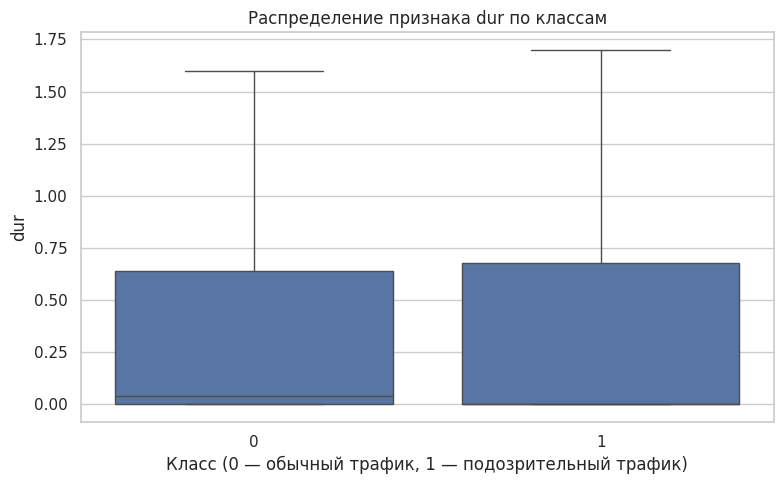

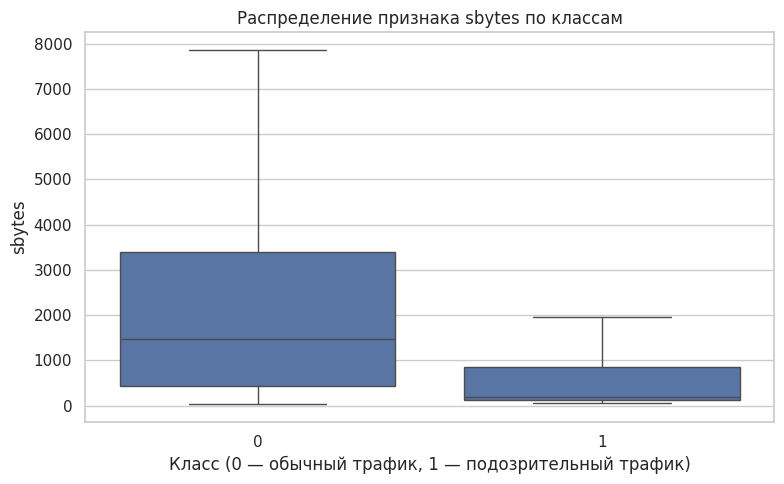

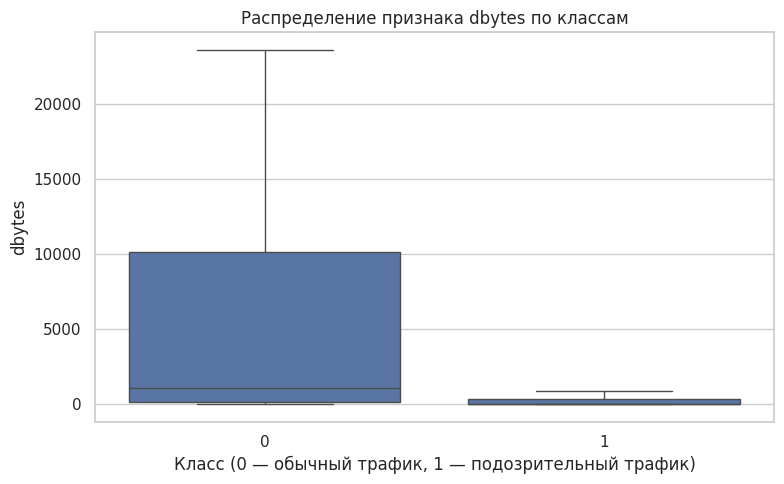

In [7]:
#3.2.Анализ числовых признаков

#dur — длительность соединения, sbytes — число байтов, переданных от источника
#dbytes — число байтов, переданных получателю
features = ["dur", "sbytes", "dbytes"]
features = [col for col in features if col in df.columns]

plot_df = df[features + ["label"]].replace(
    [np.inf, -np.inf], np.nan
).dropna()

for feature in features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=plot_df,
        x="label",
        y=feature,
        showfliers=False
    )

    plt.title(f"Распределение признака {feature} по классам")
    plt.xlabel("Класс (0 — обычный трафик, 1 — подозрительный трафик)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


На графиках показаны ящики с усами для трёх признаков. Такой график помогает быстро сравнить, как распределены значения у обычного трафика и у атак. Чёрная линия внутри ящика - это медиана, сам ящик показывает, где находится основная масса значений. Усы - границы типичного разброса.

По признаку dur (длительность соединения) графики у двух классов почти одинаковые. Медианы близки к нулю, ящики примерно одной высоты. Это значит, что по длительности соединения обычный трафик и атаки почти не отличаются.

По признаку sbytes (количество байт, отправленных источником) уже видна разница. У обычного трафика ящик выше и шире, значения в среднем больше. У подозрительного трафика ящик ниже и меньше, то есть в основном передаётся меньше данных.

По признаку dbytes (количество байт, полученных получателем) разница ещё сильнее. У обычного трафика значения сильно разбросаны и в среднем значительно больше. У подозрительного трафика почти все значения очень маленькие и близки к нулю.

По длительности (dur) классы почти не различаются, а по объёму переданных данных различия заметны. Это говорит о том, что признаки sbytes и dbytes могут быть полезны для отличия обычного трафика от атак в сочетании с другими признаками


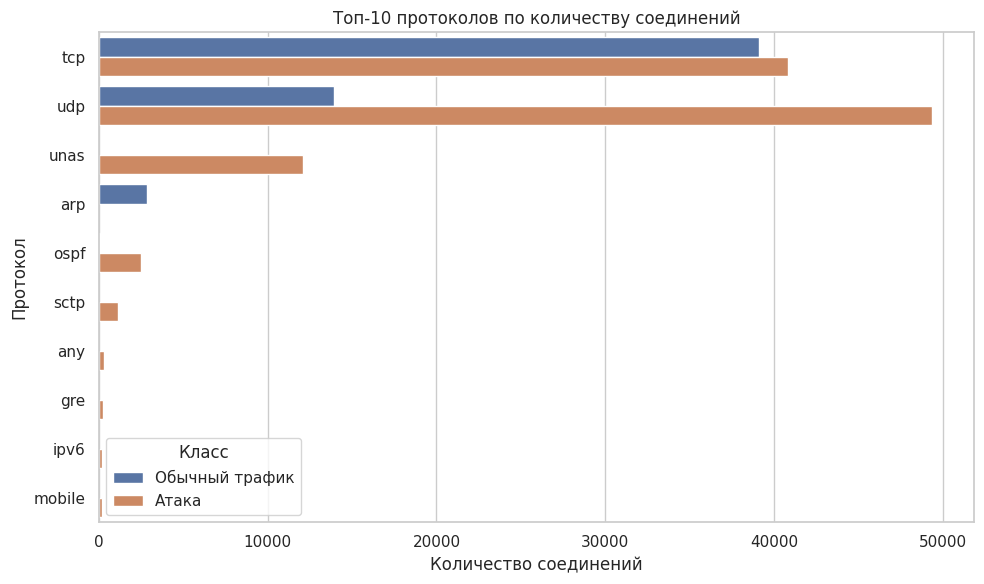

In [8]:
#3.3.Анализ протоколов

if "proto" in df.columns:
    top_protocols = df["proto"].value_counts().head(10).index
    protocol_df = df[df["proto"].isin(top_protocols)]

    plt.figure(figsize=(10, 6))

    sns.countplot(
        data=protocol_df,
        y="proto",
        hue="label",
        order=top_protocols
    )

    plt.title("Топ-10 протоколов по количеству соединений")
    plt.xlabel("Количество соединений")
    plt.ylabel("Протокол")
    plt.legend(
        title="Класс",
        labels=["Обычный трафик", "Атака"]
    )

    plt.tight_layout()
    plt.show()
else:
    print("Столбец proto не найден.")

По протоколам видно различия между классами. Некоторые протоколы, например, unas и ospf, почти полностью относятся к атакам, а arp в основном к обычному трафику. У udp атак заметно больше, чем обычных соединений. Протокол tcp встречается часто в обоих классах. Это значит, что тип протокола может помочь отличать обычный трафик от подозрительного, но не всегда, как в случае с tcp

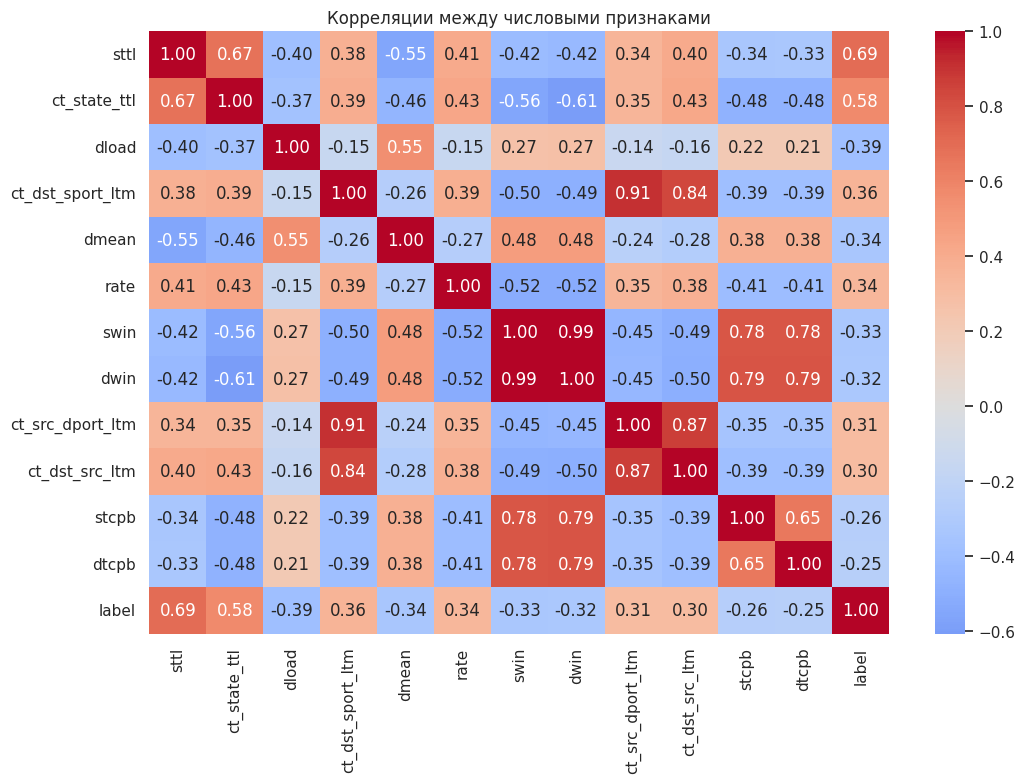

In [9]:
#3.4.Корреляция числовых признаков

numeric_df = df.select_dtypes(include="number").drop(
    columns=["id"],
    errors="ignore"
)

if "label" in numeric_df.columns:
    corr_with_label = numeric_df.corr()["label"].drop(
        labels=["label"],
        errors="ignore"
    )

    selected_features = (
        corr_with_label.abs()
        .sort_values(ascending=False)
        .head(12)
        .index.tolist()
    )

    columns_for_heatmap = selected_features + ["label"]
    corr_matrix = numeric_df[columns_for_heatmap].corr()

    plt.figure(figsize=(11, 8))
    sns.heatmap(
        corr_matrix,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )

    plt.title("Корреляции между числовыми признаками")
    plt.tight_layout()
    plt.show()
else:
    print("Столбец label не найден.")


На графике показана тепловая карта корреляций. Она показывает, насколько сильно связаны между собой числовые признаки. Красный цвет означает, что признаки растут или уменьшаются вместе, синий - что они меняются в противоположные стороны. Чем ближе число к 1 или -1, тем сильнее связь. С целевой переменной label сильнее всего связаны признаки sttl (0.69) и ct_state_ttl (0.58). Это значит, что чем выше их значения, тем чаще соединение относится к атаке. Признаки dload и dmean имеют отрицательную связь с классом — при более высоких значениях чаще встречается обычный трафик.Также на карте видно, что некоторые признаки сильно связаны между собой, например, swin и dwin имеют корреляцию 0.99. Такие признаки несут почти одинаковую информацию. Тепловая карта показывает, какие признаки больше всего связаны с атаками и какие из них похожи друг на друга. Это помогает понять, на какие признаки стоит обращать внимание при дальнейшем анализе.



## Вывод
В ходе разведочного анализа был исследован набор данных UNSW-NB15, предназначенный для изучения сетевого трафика и обнаружения атак.

Были рассмотрены структура данных, типы признаков, пропущенные значения, дубликаты и основные статистические характеристики. Распределение целевой переменной позволило оценить соотношение обычных и атакующих соединений.

С помощью диаграмм размаха были сопоставлены длительность соединений и объём переданных данных для двух классов. Анализ протоколов позволил изучить их распространённость и распределение классов, а корреляционная матрица помогла выявить линейные взаимосвязи между числовыми признаками.

По результатам исследования можно определить направления дальнейшей предобработки: проверку некорректных значений, обработку пропусков при их наличии, кодирование категориальных признаков и оценку необходимости масштабирования числовых переменных. При построении модели следует отдельно контролировать качество обнаружения атак с помощью Recall, Precision и F1-score.